# Quantum Metal 51 — four-qubit chip: a ring of TransmonPocketCLs with charge lines and coupled-pad readouts (Quantcore PDK rebuild)

**What the chip is.** Qiskit Metal `docs/circuit-examples/F.Small-quantum-chips/51-Four_qubit_chip.ipynb` (the same
layout, cell for cell, as `docs/tut/2-From-components-to-chip/2.21-Design-a-4-qubit-full-chip.ipynb`), © 2017 IBM
and contributors, Apache-2.0 (<https://github.com/qiskit-community/qiskit-metal>); spec
`docs/designs/metal/51_four_qubit_chip.md`; the id is prefixed `m` (ids do not start with a digit). We distribute the
rebuild under GPL-3.0. Four `TransmonPocketCL`s in a diamond (Q1 / Q3 at (±2.42, 0.069) mm, Q2 / Q4 at
(0, ∓0.858) mm) are joined by a ring of four 9 mm λ/2 buses; each qubit has an 8.6 mm λ/2 readout to a
`LaunchpadWirebondCoupled` and a charge line from a corner `LaunchpadWirebond` into its `Charge_Line` pin. 10/6 µm
CPW, fillet 99.99 µm.

**This notebook rebuilds it with our library and the Quantcore PDK** (PDK v3, `quantcore_nb_sapphire_v1`): the
Metal components are drawn through the `metal:<Class>` wrapper with the tutorial's own options; the chip, the stack,
the junctions, the routes, the netlist and the LOM are ours.

| | Qiskit Metal (51 / 2.21) | Quantcore PDK rebuild |
|---|---|---|
| chip | `DesignPlanar` 9 × 6.5 mm centred on (0, 0) | the same 9 × 6.5 mm box (it does not fit the 7.5 mm die), shifted by (+4.5, +3.25) mm, with the QCT die frame |
| substrate | silicon 750 µm, εr 11.45 (Metal default) | sapphire 650 µm, εr 10.25 (LOM and FEM) |
| launchpads | 8 pads, outer edge 178–230 µm from the chip edge | the same pads, moved to **100 µm** (`frame.pad_edge`) from the die edge (PDK pad rule) |
| junctions | `FakeJunction_01` GDS cell, no inductance stated | Quantcore Nb/AlOx/Nb trilayer junction, PDK nominal 0.5 × 0.6 µm (R_n 45 kΩ, L_J 6.73 nH, C_J 15 fF) |
| cheese | notebook 51 never exports a GDS (its twin 2.21 does) | the PDK band (chip `cheese: "auto"`) |
| buses / readouts | `RouteMeander` 9.0 / 8.6 mm | waypoint serpentines with Metal's 200 µm run pitch, the same total lengths |
| charge lines | `RouteAnchors`, 3277 / 4866 / 3415 / 4866 µm | the same anchors; each line ≈ 78 µm longer because its pad moved to the edge |
| placement | as drawn | content centred in the die (already centred: the pads span the die) |

**Kept exactly:** the qubits with the tutorial's options (connection pads `a`/`b`/`c` with pad widths 70 / 125 /
110 µm and `cpw_extend` 50 µm, `cl_off_center` −50 µm, `cl_pocket_edge` 180, the 69 µm off-centre shift of Q1 /
Q3), the launchpads (`lead_length` 0 / 30 µm), every position along its edge, every route's end pins and the
total lengths of the buses (9000 µm) and readouts (8600 µm).

**Simplified:** Metal's `RouteMeander`s (with ±414 … ±552 µm asymmetry that pushes each bus's meander row away from
the ring centre) are laid out as waypoint serpentines with Metal's 200 µm run pitch, sized to the same total length;
the rows sit where Metal's do (beside the north and south qubits), the readouts fill the same corners. Moving the
readout pads 88–130 µm outward lengthens the straight lead to each pad, so each readout serpentine's runs are
made a quarter of that shorter (step 6) and the readouts keep 8600 µm. The charge lines' first corner beside Q1 /
Q3 moves 83 µm outward (Metal's 120 µm lead is shorter than two 100 µm fillets).

The notebook goes step by step: PDK → die → pads → components → routes → centring → DRC → netlist → LOM →
FEM job → results back → one change re-simulated → fab export → snapshots → summary.

## 1 · Setup

The imports, the output folder and the `LIVE` switch: with KLayout open (the default), every step below is pushed to
the KLayout window as you run it; with `QCC_LIVE=0` the notebook builds headless and only writes files. `_common`
holds the small helpers the design notebooks share (tables, snapshots, the PDK placement and fab helpers).

In [1]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK placement and fab helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.lom.simulate import simulate
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
OUT = Path("examples/designs/metal")             # this notebook's design JSON and PNG snapshots
X0, Y0 = 4500, 3250                              # Metal's 9 × 6.5 mm chip is centred on (0, 0)
P = lambda x, y: (X0 + x, Y0 + y)                # Metal µm → Designer µm
R = 99.99                                        # Metal fillet
MX = lambda pts: [(2 * X0 - x, y) for x, y in pts]              # mirror x → 9000 − x
PM = lambda pts, yc=Y0: [(2 * X0 - x, 2 * yc - y) for x, y in pts]   # point mirror through (4500, yc)


def vsnake(xs, ends, y0):
    """Serpentine of vertical runs: from (xs[0], y0) run to ends[0], step to xs[1], run to ends[1], …"""
    pts = [(xs[0], y0)]
    for i, x in enumerate(xs):
        if i:
            pts.append((x, ends[i - 1]))
        pts.append((x, ends[i]))
    return pts


def hsnake(ys, ends, x0):
    """Serpentine of horizontal runs (the transpose of ``vsnake``)."""
    return [(x, y) for y, x in vsnake(ys, ends, x0)]

## 2 · The Quantcore PDK this chip uses

The rebuild takes every process fact from the PDK (`get_pdk()`), not from the source: the stack the LOM and the FEM
jobs use, the die frame, where pads go, which junction is drawn, the cheese and the 3/0 keep-outs. For this chip that means: the 9 × 6.5 mm box gets the QCT frame; the eight launchpads go 100 µm from their edges; the four qubits get the PDK nominal trilayer junction; the free ground gets the PDK cheese band.

In [2]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(name, box=...)` opens an empty chip. The box is the die (µm); the PDK draws the **QCT frame** on it: L
dicing markers in the four corners (1000/0), a 3 × 3 alignment grid in each corner area (1001/0), the chip boundary
(100/0) and the device ID `name_chip` on a free edge (optional: no free edge, no ID). Metal centres its chip on
(0, 0); our box starts at (0, 0), so every Metal position goes through `P(x, y)` = Metal + half the chip.

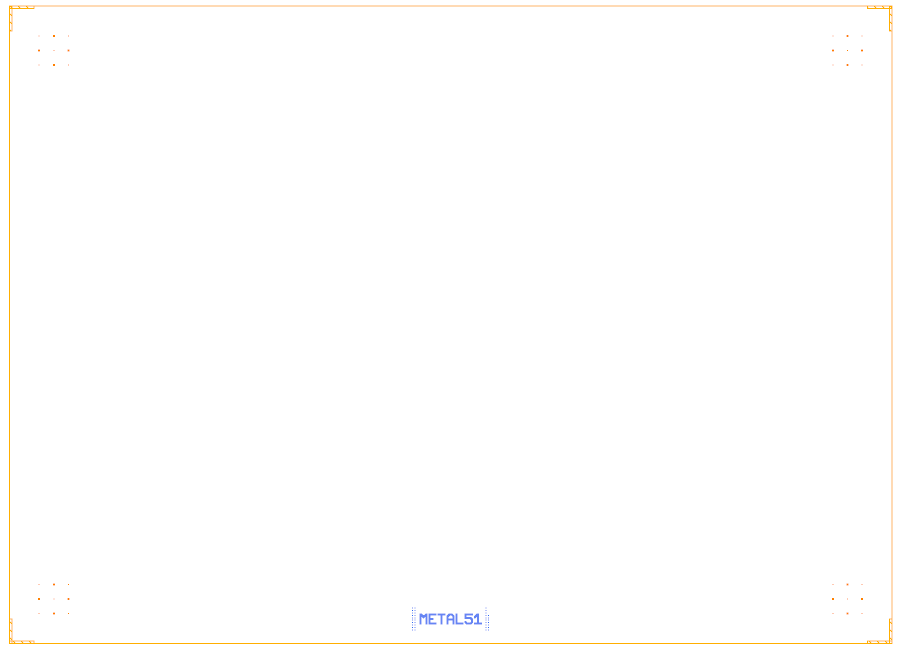

WindowsPath('examples/designs/metal/m51_four_qubit_chip_step_die.png')

In [3]:
d = Designer("m51_four_qubit_chip", box=(0, 0, 9000, 6500), chip={"name_chip": "Metal51"}, live=LIVE)
rebuild(d)                                       # build the empty die (a no-op when LIVE: it is already built)
snap(d, OUT / "m51_four_qubit_chip_step_die.png", size=(900, 650), width=450)

## 4 · Pads: the PDK pad rule

Two kinds of pad: four `LaunchpadWirebond`s at the corners for the charge lines (`P<k>_C`, `lead_length` 0) and four
`LaunchpadWirebondCoupled`s for the readouts (`P<k>_Q`, a series capacitor in the pad, `lead_length` 30 µm). In the
source their outer etch edges sit 178–230 µm in from the chip edge. In the Quantcore PDK the outer etch edge of every
bond pad sits **`frame.pad_edge` = 100 µm from the die edge**: `edge="n"` / `"s"` / `"e"` / `"w"` slides each
pad perpendicular to that edge until it is there, keeping its position along the edge. The table measures it on the
built layout.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| P1_C | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| P2_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P3_C | `metal:LaunchpadWirebond` | s | 100.0 | ✓ |
| P4_C | `metal:LaunchpadWirebond` | n | 100.0 | ✓ |
| P1_Q | `metal:LaunchpadWirebondCoupled` | e | 100.0 | ✓ |
| P2_Q | `metal:LaunchpadWirebondCoupled` | s | 100.0 | ✓ |
| P3_Q | `metal:LaunchpadWirebondCoupled` | w | 100.0 | ✓ |
| P4_Q | `metal:LaunchpadWirebondCoupled` | n | 100.0 | ✓ |

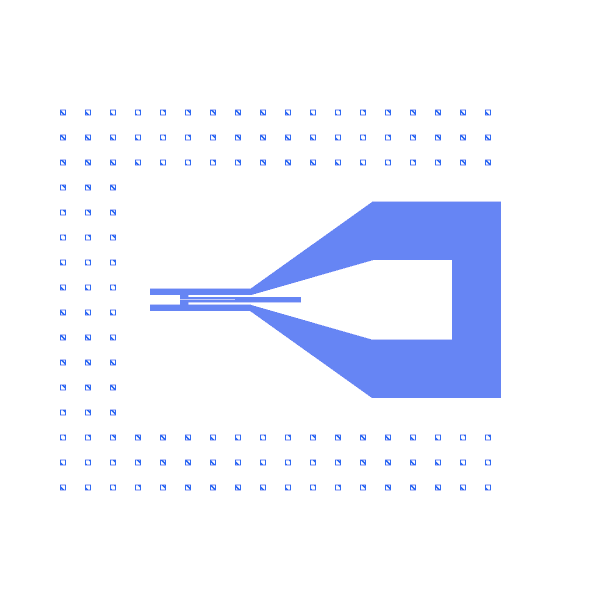

WindowsPath('examples/designs/metal/m51_four_qubit_chip_step_pads.png')

In [4]:
with d.batch():
    pc = {k: d.add(f"P{k}_C", "metal:LaunchpadWirebond", at=P(x, y), rot=r, lead_length=0, edge=e)
          for k, x, y, r, e in ((1, 3545, 2812, 270, "n"), (2, 3545, -2812, 90, "s"), (3, -3545, -2812, 90, "s"),
                                (4, -3545, 2812, 270, "n"))}
    pq = {k: d.add(f"P{k}_Q", "metal:LaunchpadWirebondCoupled", at=P(x, y), rot=r, lead_length=30, edge=e)
          for k, x, y, r, e in ((1, 4020, 0, 180, "e"), (2, -990, -2812, 90, "s"), (3, -4020, 0, 0, "w"),
                                (4, 990, 2812, 270, "n"))}
rebuild(d)
display(Markdown(pads_md(d)))
px, py = port_xy(d, "P1_Q.tie")
snap(d, OUT / "m51_four_qubit_chip_step_pads.png", box=(8400, py - 300, 9000, py + 300), size=(600, 600), width=300)

## 5 · Components: the four qubits

**The qubits.** `metal:TransmonPocketCL` is Metal's pocket transmon with a charge-line pin (`Charge_Line`), drawn by
the wrapper with the tutorial's options: three connection pads `a` (the readout, lower right), `b` and `c` (the bus
pads, lower and upper left; pad widths 70 / 125 / 110 µm, `cpw_extend` 50 µm), the charge line 50 µm off-centre at
pocket edge 180°. Q2 / Q4 are rotated 270° / 90°, Q3 by 180°, so the diamond's pads face each other.

**The junction.** With `junction_type` unset the wrapper already draws the Quantcore trilayer junction;
`trilayer_junction` makes it explicit and returns the drawn junction's L_J and C_J for the LOM and the FEM junction
port (`junction=`). The source's `FakeJunction_01` states no value, so every qubit gets the PDK nominal junction
(fingers 0.5 × 0.6 µm on 2/0 + 4/0, a 50/0 spacer with the 51–53/0 dose gradient, R_n 45 kΩ, L_J 6.73 nH,
C_J 15 fF).

Each component has named **ports** (Metal's pins): routes connect to them, and the LOM maps each to a circuit node.

junction: {'junction_type': 'Quantcore Junction'} {'Lj_nH': 6.7344, 'Cj_fF': 15.0}
Q1 ports: ['Charge_Line', 'a', 'b', 'c', 'squid_a', 'squid_b']


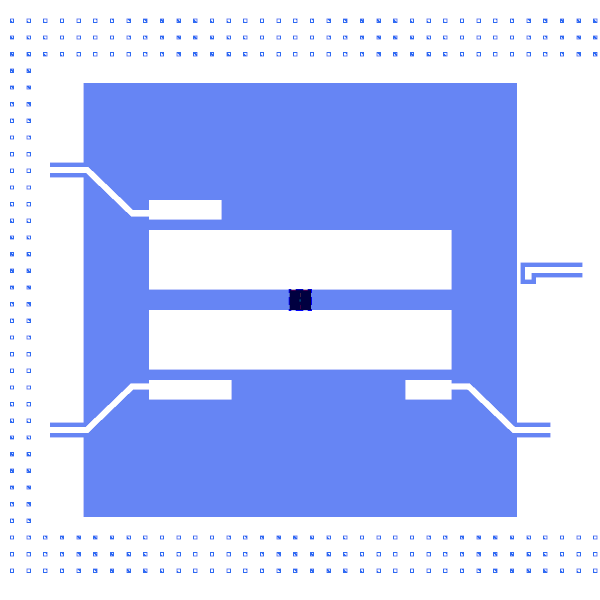

WindowsPath('examples/designs/metal/m51_four_qubit_chip_step_parts.png')

In [5]:
# Quantcore trilayer junction on the PDK rule (Nb Δ 1.4 meV): nominal fingers 0.5 × 0.6 µm → R_n 45 kΩ,
# L_J 6.73 nH, C_J 15 fF. JJ_PARAMS = {"junction_type": "Quantcore Junction"}; JUNCTION = its {Lj_nH, Cj_fF}
JJ_PARAMS, JUNCTION = trilayer_junction("metal:TransmonPocket")
print("junction:", JJ_PARAMS, JUNCTION)
with d.batch():
    tm = dict(cl_off_center=-50, cl_pocket_edge=180, junction=JUNCTION, **JJ_PARAMS,
              connection_pads={"a": {"loc_W": 1, "loc_H": -1, "pad_width": 70, "cpw_extend": 50},
                               "b": {"loc_W": -1, "loc_H": -1, "pad_width": 125, "cpw_extend": 50},
                               "c": {"loc_W": -1, "loc_H": 1, "pad_width": 110, "cpw_extend": 50}})
    offset_tm = 69                                   # the source's off-centre shift of Q1 / Q3
    q = {k: d.add(f"Q{k}", "metal:TransmonPocketCL", at=P(x, y), rot=r, **tm)
         for k, x, y, r in ((1, 2420, offset_tm, 0), (2, 0, -857.6, 270), (3, -2420, offset_tm, 180),
                            (4, 0, 857.6, 90))}
print("Q1 ports:", sorted(q[1].ports))
qx, qy = P(2420, offset_tm)
snap(d, OUT / "m51_four_qubit_chip_step_parts.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), size=(600, 600),
     width=300)

## 6 · Routes: ring buses, readouts and charge lines

- **Ring buses** (`cpw1`–`cpw4`, 9 mm λ/2 each, `meander=9000`): serpentines of eight runs at Metal's 200 µm pitch
  beside the north and south qubits, like Metal's offset meander rows; the waypoints set the path, the fixed length
  makes the router check it is 9000 µm.
- **Readouts** (`ol1`–`ol4`, 8.6 mm λ/2 to the coupled launchpads): four-run serpentines in the chip's corners. The
  pads moved 130 µm (east / west) and 88 µm (north / south) outward in step 4 (to the 100 µm
  PDK edge), so the straight lead to each pad is that much longer; each serpentine has four runs
  ending at the same extent, so moving that extent by a quarter of the pad move keeps the total at 8600 µm (`YL1`,
  `YH3`, `XL2` below: 1171.42, 5432.08 and 2309.77 µm; Metal's were 1139, 5464.5 and 2288 µm).
- **No zigzag.** The router builds every `meander` route as its waypoint path plus one KQC `Meander` on the longest
  free straight, sized to the length that is left over. A few µm left over come out as a shallow slanted zigzag
  (±25 µm over 2 mm for 75 µm), not as Metal's rounded turns. So the extents are solved to 0.01 µm: the
  waypoint path already is the full length, and the leftover (below 0.01 µm) looks like a straight line.
- **Charge lines** (`line_cl1`–`line_cl4`): Metal's `RouteAnchors` corner points; they end on the corner pads,
  so each is the pad move (78 µm) longer than Metal's.
- **Sim groups:** the ring (four qubits with the four buses, Q3D) and Q1 / Q3 with their readout and launchpad (Q3D
  and eigenmode); a box round the Q2 or Q4 readout would hold bus runs, so those two are not exported.

route lengths (µm): {'cpw1': 9000.0, 'cpw2': 9000.0, 'cpw3': 9000.0, 'cpw4': 9000.0, 'ol1': 8600.0, 'ol2': 8600.0, 'ol3': 8600.0, 'ol4': 8600.0, 'line_cl1': 3355.3, 'line_cl2': 4943.7, 'line_cl3': 3493.3, 'line_cl4': 4943.7}


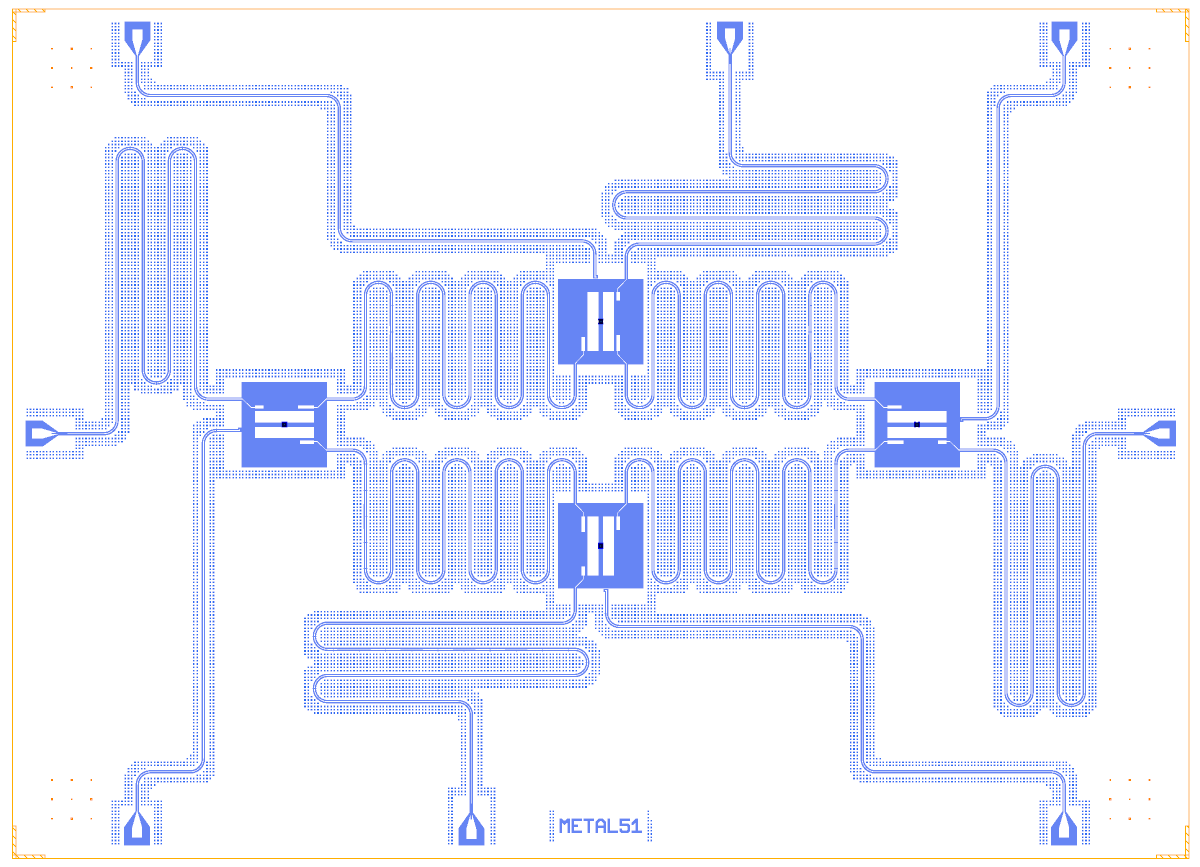

WindowsPath('examples/designs/metal/m51_four_qubit_chip_step_routes.png')

In [6]:
# serpentine extents: each route's waypoint path is its full length to < 0.01 µm (nothing is left for the router's
# length-fixing Meander to draw as a zigzag), with the pads at the PDK edge
YH, YL = 4407.6213, 2109.6288                    # bus runs (Metal: 4407.5, 2109.7)
YL1, YH3, XL2 = 1171.4175, 5432.0825, 2309.7675  # readout runs (Metal 1139, 5464.5, 2288: the pads moved outward)
with d.batch():
    # ring buses (9 mm each): serpentines of eight runs beside the north / south qubit, like Metal's offset rows
    xs = [6300 - 200 * i for i in range(8)]
    n1 = vsnake(xs, [YH, 3450] * 4, 3514) + [(4695, 3450)]          # Q1.c → Q4.b
    n4 = vsnake(xs, [YL, 3050] * 4, 3124) + [(4695, 3050)]          # Q1.b → Q2.c
    d.route("cpw1", q[1].c, q[4].b, meander=9000, r=R, nodes=n1)
    d.route("cpw2", q[3].b, q[4].c, meander=9000, r=R, nodes=MX(n1))
    d.route("cpw3", q[3].c, q[2].b, meander=9000, r=R, nodes=MX(n4))
    d.route("cpw4", q[1].b, q[2].c, meander=9000, r=R, nodes=n4)
    # λ/2 readouts (8.6 mm) to the coupled launchpads
    o1 = vsnake([7600, 7800, 8000, 8200], [YL1, 3000, YL1, 3250], 3124)
    o3 = vsnake([1400, 1200, 1000, 800], [YH3, 3638, YH3, 3250], 3514)
    o2 = [(4305, 1800)] + hsnake([1800, 1600, 1400, 1200], [XL2, 4400, XL2, 3510], 4305)[1:]
    d.route("ol1", q[1].a, pq[1].tie, meander=8600, r=R, nodes=o1)
    d.route("ol2", q[2].a, pq[2].tie, meander=8600, r=R, nodes=o2)
    d.route("ol3", q[3].a, pq[3].tie, meander=8600, r=R, nodes=o3)
    d.route("ol4", q[4].a, pq[4].tie, meander=8600, r=R, nodes=PM(o2))
    # charge lines (Metal RouteAnchors paths) into the Charge_Line pins
    d.route("line_cl1", q[1].Charge_Line, pc[1].tie, r=R, nodes=[(7540, 3364), (7540, 5837), (8045, 5837)])
    d.route("line_cl2", q[2].Charge_Line, pc[2].tie, r=R, nodes=[(4545, 1775), (6500, 1775), (6500, 663), (8045, 663)])
    d.route("line_cl3", q[3].Charge_Line, pc[3].tie, r=R, nodes=[(1460, 3274), (1460, 663), (955, 663)])
    d.route("line_cl4", q[4].Charge_Line, pc[4].tie, r=R,
            nodes=PM([(4545, 1775), (6500, 1775), (6500, 663), (8045, 663)]))
# FEM boxes: margins chosen so that each box cuts every other line once (Q2 / Q4 readout boxes would hold bus runs)
d.sim_group("ring", ["Q1", "Q2", "Q3", "Q4", "cpw1", "cpw2", "cpw3", "cpw4"], margin_um=150, analyses=["q3d_cmatrix"])
for k in (1, 3):
    d.sim_group(f"Q{k}_read", [f"Q{k}", f"ol{k}", f"P{k}_Q"], margin_um=30, analyses=["q3d_cmatrix", "eigenmode_epr"])
rebuild(d)
print("route lengths (µm):", {k: round(v, 1) for k, v in d.result.route_lengths().items()})
snap(d, OUT / "m51_four_qubit_chip_step_routes.png", size=(1200, 867), width=480)

## 7 · Centre the content and save

The PDK wants the chip content centred in the die. `center_in_die` measures the bounding box of everything placed
(components and routes) and shifts the design so its centre is the die centre (pads keep their 100 µm: they slide
back to the edge along it). Here the pads span the die in both directions and the source is symmetric, so nothing
moves. Then the design is saved: the JSON is the deliverable.

In [7]:
shift = center_in_die(d)
rebuild(d)
print("content shifted by", shift, "µm")
DESIGN = d.save(OUT / "m51_four_qubit_chip.json")
print(d, "→", DESIGN)

content shifted by (0.0, 0.0) µm
<Designer m51_four_qubit_chip: 12 instances, 12 routes, live=False> → examples\designs\metal\m51_four_qubit_chip.json


## 8 · DRC

`d.drc()` checks connectivity (every port routed or snapped, route ends resolved), crossings, overlaps, the chip
box and the frame. It has three kinds of findings:
- **errors** (open, short, crossing, outside the chip): the design is broken; there must be none;
- **warnings** (an unused port, two component boxes overlapping): worth a look, often by design;
- **PDK design warnings** (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): the design is valid but leaves a PDK
  margin. They are flagged, never fixed by retuning: the values are the source's.

Expected here: **no errors**, eight `dangling_port` warnings (`Q<k>.squid_a` / `squid_b`, the junction's
attachment points: the qubit cell draws the junction itself, nothing is routed there) and **no PDK design
warnings** (the pads are at 100 µm, the nominal junction is in the R_n window, the design sets no targets).

`pdk_report(d)` sums up the PDK side: the cheese source, how far the content centre is from the die centre, the
junction types and the design warnings.

In [8]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))

**0 errors · 8 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|
| warning | `dangling_port` | 8 | Q1.squid_a is not connected (no route or snap) |

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 4 |
| PDK design warnings | 0 (none) |

## 9 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: each `TransmonPocketCL` gives two floating pad nodes with the
junction between them, a node per connection pad, and the `Charge_Line` as a drive port; each bus between two pads
and each readout between a pad and a coupled launchpad (series C to its 50 Ω port) is a λ/2 `TLres`; the charge
lines end on their 50 Ω pads. The port map shows which node each of Q1's ports landed on.

In [9]:
lb = d.lom()
show_netlist(lb)
print({k: v for k, v in lb.port_map.items() if k.startswith(("Q1.", "P1_"))})

**25 nodes · 80 branches · 4 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `P1_C.pad` | `P1_C.pad` |
| `P2_C.pad` | `P2_C.pad` |
| `P3_C.pad` | `P3_C.pad` |
| `P4_C.pad` | `P4_C.pad` |
| `P1_Q.pad` | `P1_Q.pad` |
| `P1_Q.tie` | `P1_Q.tie`, `Q1.a` |
| `P2_Q.pad` | `P2_Q.pad` |
| `P2_Q.tie` | `P2_Q.tie`, `Q2.a` |
| `P3_Q.pad` | `P3_Q.pad` |
| `P3_Q.tie` | `P3_Q.tie`, `Q3.a` |
| `P4_Q.pad` | `P4_Q.pad` |
| `P4_Q.tie` | `P4_Q.tie`, `Q4.a` |
| `Q1.island1` | `Q1.island1` |
| `Q1.island2` | `Q1.island2` |
| `Q1.b` | `Q1.b`, `Q2.c` |
| `Q1.c` | `Q1.c`, `Q4.b` |
| `Q2.island1` | `Q2.island1` |
| `Q2.island2` | `Q2.island2` |
| `Q2.b` | `Q2.b`, `Q3.c` |
| `Q3.island1` | `Q3.island1` |
| `Q3.island2` | `Q3.island2` |
| `Q3.b` | `Q3.b`, `Q4.c` |
| `Q4.island1` | `Q4.island1` |
| `Q4.island2` | `Q4.island2` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_P1_C` | R | `P1_C.pad` – `gnd` | 50 Ω |
| `Port_P2_C` | R | `P2_C.pad` – `gnd` | 50 Ω |
| `Port_P3_C` | R | `P3_C.pad` – `gnd` | 50 Ω |
| `Port_P4_C` | R | `P4_C.pad` – `gnd` | 50 Ω |
| `Port_P1_Q` | R | `P1_Q.pad` – `gnd` | 50 Ω |
| `Ck_P1_Q` | C | `P1_Q.pad` – `P1_Q.tie` | 11 fF |
| `C_P1_Q_tie` | C | `P1_Q.tie` – `gnd` | 4.4 fF |
| `Port_P2_Q` | R | `P2_Q.pad` – `gnd` | 50 Ω |
| `Ck_P2_Q` | C | `P2_Q.pad` – `P2_Q.tie` | 11 fF |
| `C_P2_Q_tie` | C | `P2_Q.tie` – `gnd` | 4.4 fF |
| `Port_P3_Q` | R | `P3_Q.pad` – `gnd` | 50 Ω |
| `Ck_P3_Q` | C | `P3_Q.pad` – `P3_Q.tie` | 11 fF |
| `C_P3_Q_tie` | C | `P3_Q.tie` – `gnd` | 4.4 fF |
| `Port_P4_Q` | R | `P4_Q.pad` – `gnd` | 50 Ω |
| `Ck_P4_Q` | C | `P4_Q.pad` – `P4_Q.tie` | 11 fF |
| `C_P4_Q_tie` | C | `P4_Q.tie` – `gnd` | 4.4 fF |
| `C_Q1_1` | C | `Q1.island1` – `gnd` | 36 fF |
| `C_Q1_2` | C | `Q1.island2` – `gnd` | 36 fF |
| `C_Q1_12` | C | `Q1.island1` – `Q1.island2` | 27.7 fF |
| `J_Q1` | JJ | `Q1.island1` – `Q1.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q1_a` | C | `Q1.island2` – `P1_Q.tie` | 8.63 fF |
| `Cf_Q1_a` | C | `Q1.island1` – `P1_Q.tie` | 0.91 fF |
| `Cc_Q1_a` | C | `P1_Q.tie` – `gnd` | 22.7 fF |
| `Cg_Q1_b` | C | `Q1.island2` – `Q1.b` | 17.3 fF |
| `Cf_Q1_b` | C | `Q1.island1` – `Q1.b` | 1.8 fF |
| `Cc_Q1_b` | C | `Q1.b` – `gnd` | 26 fF |
| `Cg_Q1_c` | C | `Q1.island1` – `Q1.c` | 14.8 fF |
| `Cf_Q1_c` | C | `Q1.island2` – `Q1.c` | 1.5 fF |
| `Cc_Q1_c` | C | `Q1.c` – `gnd` | 25.2 fF |
| `C_Q2_1` | C | `Q2.island1` – `gnd` | 36 fF |
| `C_Q2_2` | C | `Q2.island2` – `gnd` | 36 fF |
| `C_Q2_12` | C | `Q2.island1` – `Q2.island2` | 27.7 fF |
| `J_Q2` | JJ | `Q2.island1` – `Q2.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q2_a` | C | `Q2.island2` – `P2_Q.tie` | 8.63 fF |
| `Cf_Q2_a` | C | `Q2.island1` – `P2_Q.tie` | 0.91 fF |
| `Cc_Q2_a` | C | `P2_Q.tie` – `gnd` | 22.7 fF |
| `Cg_Q2_b` | C | `Q2.island2` – `Q2.b` | 17.3 fF |
| `Cf_Q2_b` | C | `Q2.island1` – `Q2.b` | 1.8 fF |
| `Cc_Q2_b` | C | `Q2.b` – `gnd` | 26 fF |
| `Cg_Q2_c` | C | `Q2.island1` – `Q1.b` | 14.8 fF |
| `Cf_Q2_c` | C | `Q2.island2` – `Q1.b` | 1.5 fF |
| `Cc_Q2_c` | C | `Q1.b` – `gnd` | 25.2 fF |
| `C_Q3_1` | C | `Q3.island1` – `gnd` | 36 fF |
| `C_Q3_2` | C | `Q3.island2` – `gnd` | 36 fF |
| `C_Q3_12` | C | `Q3.island1` – `Q3.island2` | 27.7 fF |
| `J_Q3` | JJ | `Q3.island1` – `Q3.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q3_a` | C | `Q3.island2` – `P3_Q.tie` | 8.63 fF |
| `Cf_Q3_a` | C | `Q3.island1` – `P3_Q.tie` | 0.91 fF |
| `Cc_Q3_a` | C | `P3_Q.tie` – `gnd` | 22.7 fF |
| `Cg_Q3_b` | C | `Q3.island2` – `Q3.b` | 17.3 fF |
| `Cf_Q3_b` | C | `Q3.island1` – `Q3.b` | 1.8 fF |
| `Cc_Q3_b` | C | `Q3.b` – `gnd` | 26 fF |
| `Cg_Q3_c` | C | `Q3.island1` – `Q2.b` | 14.8 fF |
| `Cf_Q3_c` | C | `Q3.island2` – `Q2.b` | 1.5 fF |
| `Cc_Q3_c` | C | `Q2.b` – `gnd` | 25.2 fF |
| `C_Q4_1` | C | `Q4.island1` – `gnd` | 36 fF |
| `C_Q4_2` | C | `Q4.island2` – `gnd` | 36 fF |
| `C_Q4_12` | C | `Q4.island1` – `Q4.island2` | 27.7 fF |
| `J_Q4` | JJ | `Q4.island1` – `Q4.island2` | Lj 6.73 nH, Cj 15 fF |
| `Cg_Q4_a` | C | `Q4.island2` – `P4_Q.tie` | 8.63 fF |
| `Cf_Q4_a` | C | `Q4.island1` – `P4_Q.tie` | 0.91 fF |
| `Cc_Q4_a` | C | `P4_Q.tie` – `gnd` | 22.7 fF |
| `Cg_Q4_b` | C | `Q4.island2` – `Q1.c` | 17.3 fF |
| `Cf_Q4_b` | C | `Q4.island1` – `Q1.c` | 1.8 fF |
| `Cc_Q4_b` | C | `Q1.c` – `gnd` | 26 fF |
| `Cg_Q4_c` | C | `Q4.island1` – `Q3.b` | 14.8 fF |
| `Cf_Q4_c` | C | `Q4.island2` – `Q3.b` | 1.5 fF |
| `Cc_Q4_c` | C | `Q3.b` – `gnd` | 25.2 fF |
| `Cd_Q1` | C | `Q1.island1` – `P1_C.pad` | 0.1 fF |
| `Cd_Q2` | C | `Q2.island1` – `P2_C.pad` | 0.1 fF |
| `Cd_Q3` | C | `Q3.island1` – `P3_C.pad` | 0.1 fF |
| `Cd_Q4` | C | `Q4.island1` – `P4_C.pad` | 0.1 fF |
| `cpw1` | TLres | `Q1.c` – `gnd` | lambda/2, 9000 µm, 7.002 GHz |
| `cpw2` | TLres | `Q3.b` – `gnd` | lambda/2, 9000 µm, 7.002 GHz |
| `cpw3` | TLres | `Q2.b` – `gnd` | lambda/2, 9000 µm, 7.002 GHz |
| `cpw4` | TLres | `Q1.b` – `gnd` | lambda/2, 9000 µm, 7.002 GHz |
| `ol1` | TLres | `P1_Q.tie` – `gnd` | lambda/2, 8600 µm, 7.328 GHz |
| `ol2` | TLres | `P2_Q.tie` – `gnd` | lambda/2, 8600 µm, 7.328 GHz |
| `ol3` | TLres | `P3_Q.tie` – `gnd` | lambda/2, 8600 µm, 7.328 GHz |
| `ol4` | TLres | `P4_Q.tie` – `gnd` | lambda/2, 8600 µm, 7.328 GHz |

| control | kind | target | line | length (µm) |
|---|---|---|---|---|
| `line_cl1` | drive | `J_Q1` | `line_cl1` | 3355 |
| `line_cl2` | drive | `J_Q2` | `line_cl2` | 4944 |
| `line_cl3` | drive | `J_Q3` | `line_cl3` | 3493 |
| `line_cl4` | drive | `J_Q4` | `line_cl4` | 4944 |

**Unconnected ports:** none

{'P1_C.tie': 'P1_C.pad', 'P1_Q.tie': 'P1_Q.tie', 'Q1.squid_a': 'Q1.island2', 'Q1.squid_b': 'Q1.island1', 'Q1.a': 'P1_Q.tie', 'Q1.b': 'Q1.b', 'Q1.c': 'Q1.c', 'Q1.Charge_Line': 'control:drive'}


## 10 · LOM simulation

QuCat solves each sub-circuit's normal modes (frequency, κ through the 50 Ω ports, anharmonicity); QuTiP diagonalises
the dressed Hamiltonian for f_q, α, f_r and χ. First each qubit with its readout, launchpad and charge line; then
each ring bus with the two qubits it joins (static ZZ).

With the PDK junction (6.73 nH, 15 fF) the four identical qubits sit near 7.1 GHz, above the ≈ 6.6 GHz λ/2 buses and
≈ 0.1 GHz above their 7.0 GHz readouts (the pre-rebuild build assumed 10 nH and had them at 6.3 GHz). Identical
qubits on one bus hybridise (the per-pair ZZ is then "hybridised", not defined). The source states no targets.

In [10]:
read = {f"Q{k}+ol{k}": [f"Q{k}", f"ol{k}", f"P{k}_Q", f"line_cl{k}", f"P{k}_C"] for k in (1, 2, 3, 4)}
results = simulate_groups(d, read)
display(Markdown(groups_md(results)))
ring = {"Q1+cpw1+Q4": ["Q1", "cpw1", "Q4"], "Q3+cpw2+Q4": ["Q3", "cpw2", "Q4"],
        "Q3+cpw3+Q2": ["Q3", "cpw3", "Q2"], "Q1+cpw4+Q2": ["Q1", "cpw4", "Q2"]}
coupled = simulate_groups(d, ring, max_modes=3)
for g, res in coupled.items():
    display(Markdown(f"**{g}, QuCat normal modes:**\n\n" + modes_md(res)))
display(Markdown("**Static ZZ (QuTiP):**\n\n" + zz_md(coupled)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+ol1 | Q1 | 7.1264 | -437 | ol1 | 7.0122 | 2.74 | 86.4 |
| Q2+ol2 | Q2 | 7.1264 | -437 | ol2 | 7.0122 | 2.74 | 86.4 |
| Q3+ol3 | Q3 | 7.1264 | -437 | ol3 | 7.0122 | 2.74 | 86.4 |
| Q4+ol4 | Q4 | 7.1264 | -437 | ol4 | 7.0122 | 2.74 | 86.4 |

**Q1+cpw1+Q4, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| cpw1 | resonator | 6.5788 | 0 | 0.1 | cpw1 0.96, J_Q1 0.02, J_Q4 0.02 |
| Q1 | qubit | 7.3259 | 0 | 141.5 | J_Q1 0.58, J_Q4 0.42 |
| Q4 | qubit | 7.3593 | 0 | 133.1 | J_Q4 0.56, J_Q1 0.40, cpw1 0.04 |

**Q3+cpw2+Q4, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| cpw2 | resonator | 6.5788 | 0 | 0.1 | cpw2 0.96, J_Q4 0.02, J_Q3 0.02 |
| Q4 | qubit | 7.3259 | 0 | 141.5 | J_Q4 0.58, J_Q3 0.42 |
| Q3 | qubit | 7.3593 | 0 | 133.1 | J_Q3 0.56, J_Q4 0.40, cpw2 0.04 |

**Q3+cpw3+Q2, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| cpw3 | resonator | 6.5788 | 0 | 0.1 | cpw3 0.96, J_Q3 0.02, J_Q2 0.02 |
| Q3 | qubit | 7.3259 | 0 | 141.5 | J_Q3 0.58, J_Q2 0.42 |
| Q2 | qubit | 7.3593 | 0 | 133.1 | J_Q2 0.56, J_Q3 0.40, cpw3 0.04 |

**Q1+cpw4+Q2, QuCat normal modes:**

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| cpw4 | resonator | 6.5788 | 0 | 0.1 | cpw4 0.96, J_Q2 0.02, J_Q1 0.02 |
| Q2 | qubit | 7.3259 | 0 | 141.5 | J_Q2 0.58, J_Q1 0.42 |
| Q1 | qubit | 7.3593 | 0 | 133.1 | J_Q1 0.56, J_Q2 0.40, cpw4 0.04 |

**Static ZZ (QuTiP):**

| group | pair | ZZ (kHz) | neighbours | hybridised |
|---|---|---|---|---|
| Q1+cpw1+Q4 | Q1-Q4 | – | yes | yes |
| Q3+cpw2+Q4 | Q3-Q4 | – | yes | yes |
| Q3+cpw3+Q2 | Q2-Q3 | – | yes | yes |
| Q1+cpw4+Q2 | Q1-Q2 | – | yes | yes |

## 11 · FEM: send the job

The LOM uses analytic capacitance estimates; a finite-element job measures them. `export_sims` cuts each sim group
out of the chip (the box set by `sim_group`), puts ports where lines leave the box and writes a job folder under
`build/jobs/`. Simulation exports never get cheese, and airbridges are dropped unless asked for.

Q3D C-matrix jobs for every sim group (`ring`: the four qubits with the four buses; `Q1_read`, `Q3_read`: the
qubit with its readout and launchpad) and eigenmode / EPR jobs for `Q1_read` and `Q3_read` (the lines leaving the
box end in 50 Ω, so the mode Q gives κ).

`RUN_FEM = False` keeps the notebook fast. Set it to `True` to solve the jobs here: `send_fem_jobs` finds AEDT 2024
R1 (or newer) and solves each Ansys job in a **new batch, non-graphical** AEDT, so an AEDT window you have open is
never touched. The command-line equivalent is `qcc hfss solve build/jobs/<job>`.

In [11]:
jobs = export_sims(DESIGN)
jobs_eig = export_sims(DESIGN, ["Q1_read", "Q3_read"], analysis="eigenmode_epr")
display(Markdown(jobs_md(jobs) + "\n" + jobs_md(jobs_eig).split("\n", 2)[2]))

| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| ring | `build/jobs/m51_four_qubit_chip_ring_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · junction · `Q2.junction`<br>3 · junction · `Q3.junction`<br>4 · junction · `Q4.junction`<br>5 · waveguide · `Q1.c`<br>6 · waveguide · `Q4.b`<br>7 · waveguide · `Q3.b`<br>8 · waveguide · `Q4.c`<br>9 · waveguide · `Q3.c`<br>10 · waveguide · `Q2.b`<br>11 · waveguide · `Q1.b`<br>12 · waveguide · `Q2.c`<br>13 · edge · `line_cl1`<br>14 · edge · `line_cl2`<br>15 · edge · `line_cl3`<br>16 · edge · `line_cl4`<br>17 · edge · `ol1`<br>18 · edge · `ol2`<br>19 · edge · `ol3`<br>20 · edge · `ol4` | `Q1.island2`, `Q2.island2`, `Q3.island2`, `Q4.island2`, `Q1.c`, `Q4.b`, `Q3.b`, `Q4.c`, `Q3.c`, `Q2.b`, `Q1.b`, `Q2.c`, `line_cl1`, `line_cl2`, `line_cl3`, `line_cl4`, `ol1`, `ol2`, `ol3`, `ol4`, `Q2.island1`, `Q3.island1`, `Q1.island1`, `Q4.island1` |
| Q1_read | `build/jobs/m51_four_qubit_chip_Q1_read_q3d_cmatrix` | 1 · junction · `Q1.junction`<br>2 · waveguide · `Q1.a`<br>3 · waveguide · `P1_Q.tie`<br>4 · edge · `cpw1`<br>5 · edge · `cpw4`<br>6 · edge · `line_cl1`<br>7 · lumped · `P1_Q.pad` | `Q1.island2`, `Q1.a`, `P1_Q.tie`, `cpw1`, `cpw4`, `line_cl1`, `P1_Q.pad`, `Q1.island1` |
| Q3_read | `build/jobs/m51_four_qubit_chip_Q3_read_q3d_cmatrix` | 1 · junction · `Q3.junction`<br>2 · waveguide · `Q3.a`<br>3 · waveguide · `P3_Q.tie`<br>4 · edge · `cpw2`<br>5 · edge · `cpw3`<br>6 · edge · `line_cl3`<br>7 · lumped · `P3_Q.pad` | `Q3.island2`, `Q3.a`, `P3_Q.tie`, `cpw2`, `cpw3`, `line_cl3`, `P3_Q.pad`, `Q3.island1` |
| Q1_read | `build/jobs/m51_four_qubit_chip_Q1_read_eigenmode_epr` | 1 · junction · `Q1.junction`<br>2 · edge_lumped · `cpw1`<br>3 · edge_lumped · `cpw4`<br>4 · edge_lumped · `line_cl1`<br>5 · lumped · `P1_Q.pad` | `Q1.island2`, `cpw1`, `cpw4`, `line_cl1`, `P1_Q.pad`, `Q1.a`, `Q1.island1` |
| Q3_read | `build/jobs/m51_four_qubit_chip_Q3_read_eigenmode_epr` | 1 · junction · `Q3.junction`<br>2 · edge_lumped · `cpw2`<br>3 · edge_lumped · `cpw3`<br>4 · edge_lumped · `line_cl3`<br>5 · lumped · `P3_Q.pad` | `Q3.island2`, `cpw2`, `cpw3`, `line_cl3`, `P3_Q.pad`, `Q3.island1`, `Q3.a` |

In [12]:
RUN_FEM = False   # True: solve the jobs now in a new batch AEDT (2024 R1 or newer)
if RUN_FEM:
    send_fem_jobs(DESIGN, ['ring', 'Q1_read', 'Q3_read'], run=True)

## 12 · Bring the FEM results back

When a job has been solved, its folder holds `results/results.json`. `fem_back` fills the LOM with the extracted
C-matrix (matched by net name: the job's nets are the LOM's nodes) and lists each capacitance as estimate vs
extracted. Without results it says what would appear; the LOM values above stay the estimates.

In [13]:
filled, back_md = fem_back(lb.model, DESIGN, {**{f"{g} · q3d": v for g, v in jobs.items()}, **{f"{g} · eigenmode": v for g, v in jobs_eig.items()}})
display(Markdown(back_md))
for key, fc in filled.items():                   # re-simulate the LOM on the extracted values
    display(Markdown(f"**{key}, LOM on the FEM values:**"))
    display(Markdown(modes_md(simulate(fc))))

No FEM results yet for ring · q3d, Q1_read · q3d, Q3_read · q3d, Q1_read · eigenmode, Q3_read · eigenmode: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 13 · Iterate: change one property and re-simulate

A design loop in one cell: copy the saved design (`design_copy`: a non-live Designer that never writes over the
JSON), change one property — here Q1's readout pad `a`, 70 → 120 µm wide — rebuild, re-run the LOM of Q1 with its
readout and compare. A wider pad couples Q1 more strongly to its readout and loads both: f_r and f_q drop and |χ|
grows. (With the PDK junction Q1 sits only ≈ 110 MHz above its readout, so χ here is near-resonant, not a dispersive
shift: the values are the source's geometry with the PDK junction, flagged, not retuned.)

In [14]:
d2 = design_copy(DESIGN)
pads = dict(d2.data["instances"]["Q1"]["params"]["connection_pads"])
pads["a"] = {**pads["a"], "pad_width": 120}      # 70 → 120 µm
d2["Q1"].set(connection_pads=pads)
group = {"Q1+ol1": read["Q1+ol1"]}
after = simulate_groups(d2, group)
display(Markdown(params_delta_md({"Q1+ol1": results["Q1+ol1"]}, after)))

| parameter | before | after | Δ |
|---|---|---|---|
| `Q1+ol1: ol1.f_GHz` | 7.0122 | 6.9047 | -0.1075 |
| `Q1+ol1: ol1.kappa_MHz` | 2.7353 | 2.4318 | -0.3035 |
| `Q1+ol1: ol1.chi_MHz` | 86.357 | 170.44 | +84.08 |
| `Q1+ol1: Q1.f_q_GHz` | 7.1264 | 7.1015 | -0.02485 |
| `Q1+ol1: Q1.alpha_MHz` | -436.96 | -580.09 | -143.1 |

## 14 · Build and export

The design JSON saved in step 7 is the deliverable: `qcc build`, `qcc mask` and the KLayout plugin all read it.
The fab export writes only the PDK fab layers (1/0 etch, 3/0 keep-out, 2/0 + 4/0 junction fingers, 50–53/0 spacer,
100/0 chip boundary, 1000/0 + 1001/0 frame markers), with corner rounding and the cheese.

**Cheese.** Notebook 51 never exports a GDS, so the original has no cheese: the PDK band applies
(`cheese: "auto"`, the default). (Its twin, tutorial 2.21, exports with Metal's default GDS cheese; the rebuild
follows notebook 51, the source named in the spec.) The build draws the band into KQC's `ground_grid` layer (5 µm
squares, 20 µm gaps, three rows round the 3/0 keep-outs) and `export_fab` keeps it (`cheese source: build`).

Command-line equivalents:
- `qcc build examples/designs/metal/<id>.json` (the layout and its KLayout sidecar);
- `qcc mask examples/designs/metal/<id>.json` (the fab file; `--no-cheese`, `--no-round`);
- `qcc sim build examples/designs/metal/<id>.json -g <group> -a q3d_cmatrix` (one FEM job).

In [15]:
print("design file:", DESIGN)
CHEESE = True
display(Markdown(fab_layers_md(d, cheese=CHEESE, rounding=True)))

design file: examples\designs\metal\m51_four_qubit_chip.json


| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 21679 |
| 2/0 | JJ_STRAIGHT | 4 |
| 3/0 | M3 | 21669 |
| 4/0 | JJ_BENT | 4 |
| 50/0 | HSQ | 8 |
| 51/0 | SPACER_1 | 8 |
| 52/0 | SPACER_2 | 8 |
| 53/0 | SPACER_3 | 8 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 21667 holes on the mask.

→ `build/m51_four_qubit_chip_fab.oas`

## 15 · Snapshots

The full chip (compare the tutorial's screenshot); Q1 with its pads and charge line; its trilayer junction; the Q1
readout's coupled launchpad at the east edge; the **fab mask** round Q1 (1/0 etch with the PDK cheese band, the 3/0
keep-out, the junction layers); and the die frame's south-west corner (dicing L on 1000/0, alignment grid on
1001/0). Positions are read from the design.

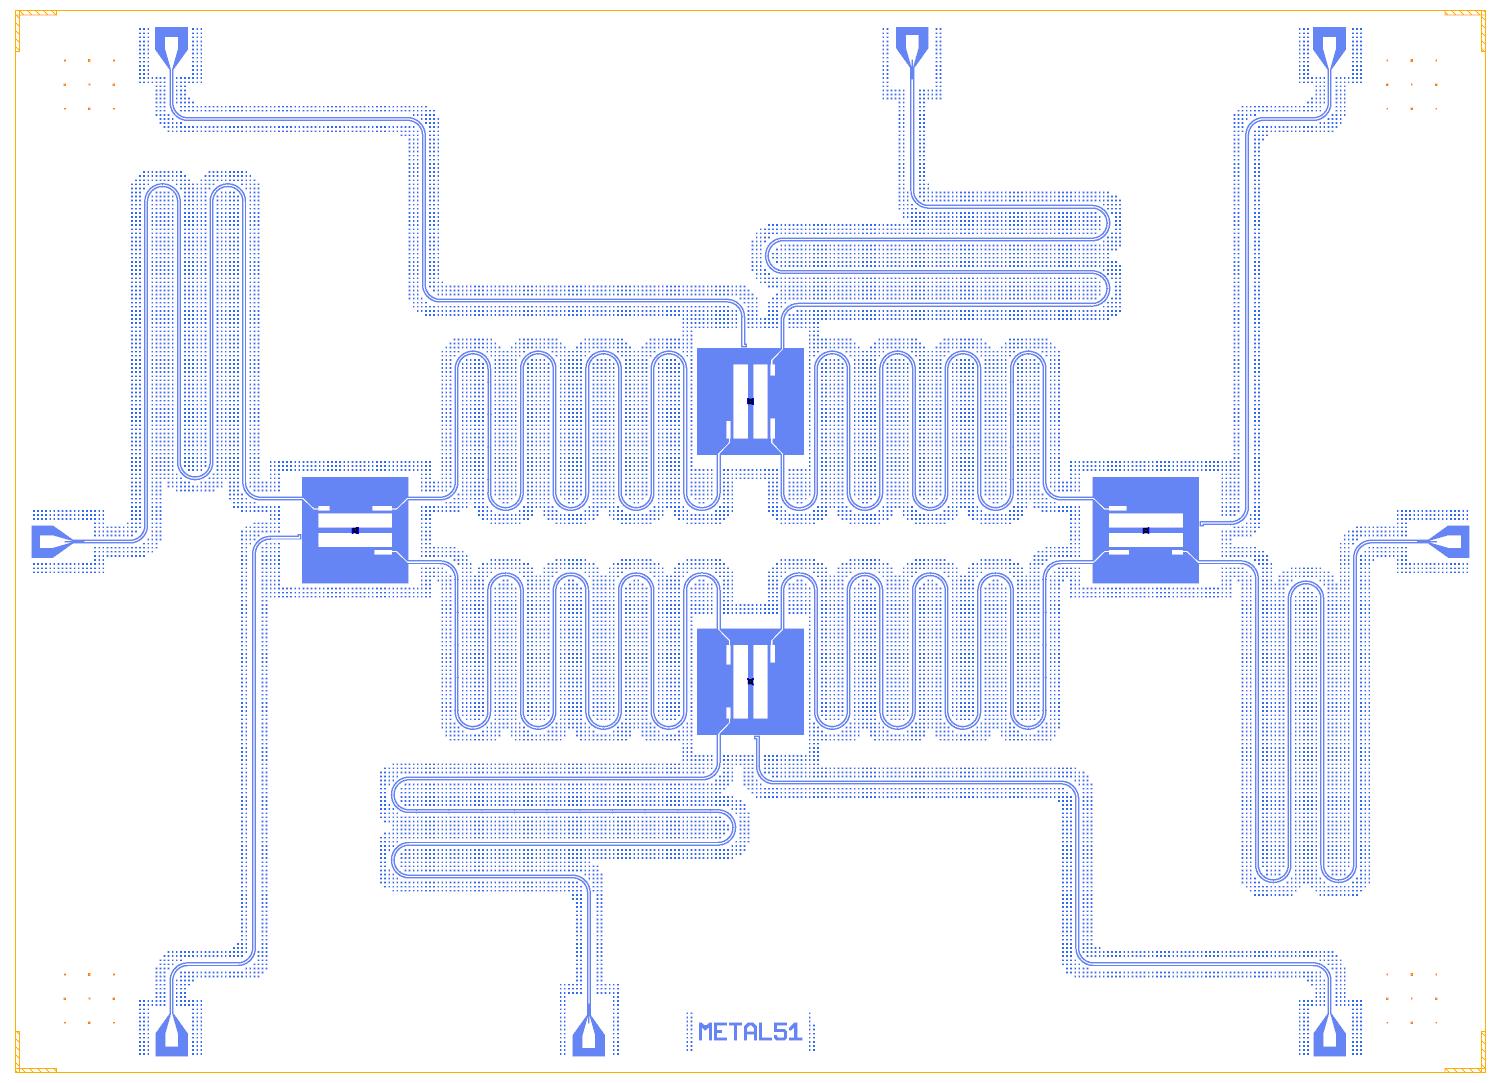

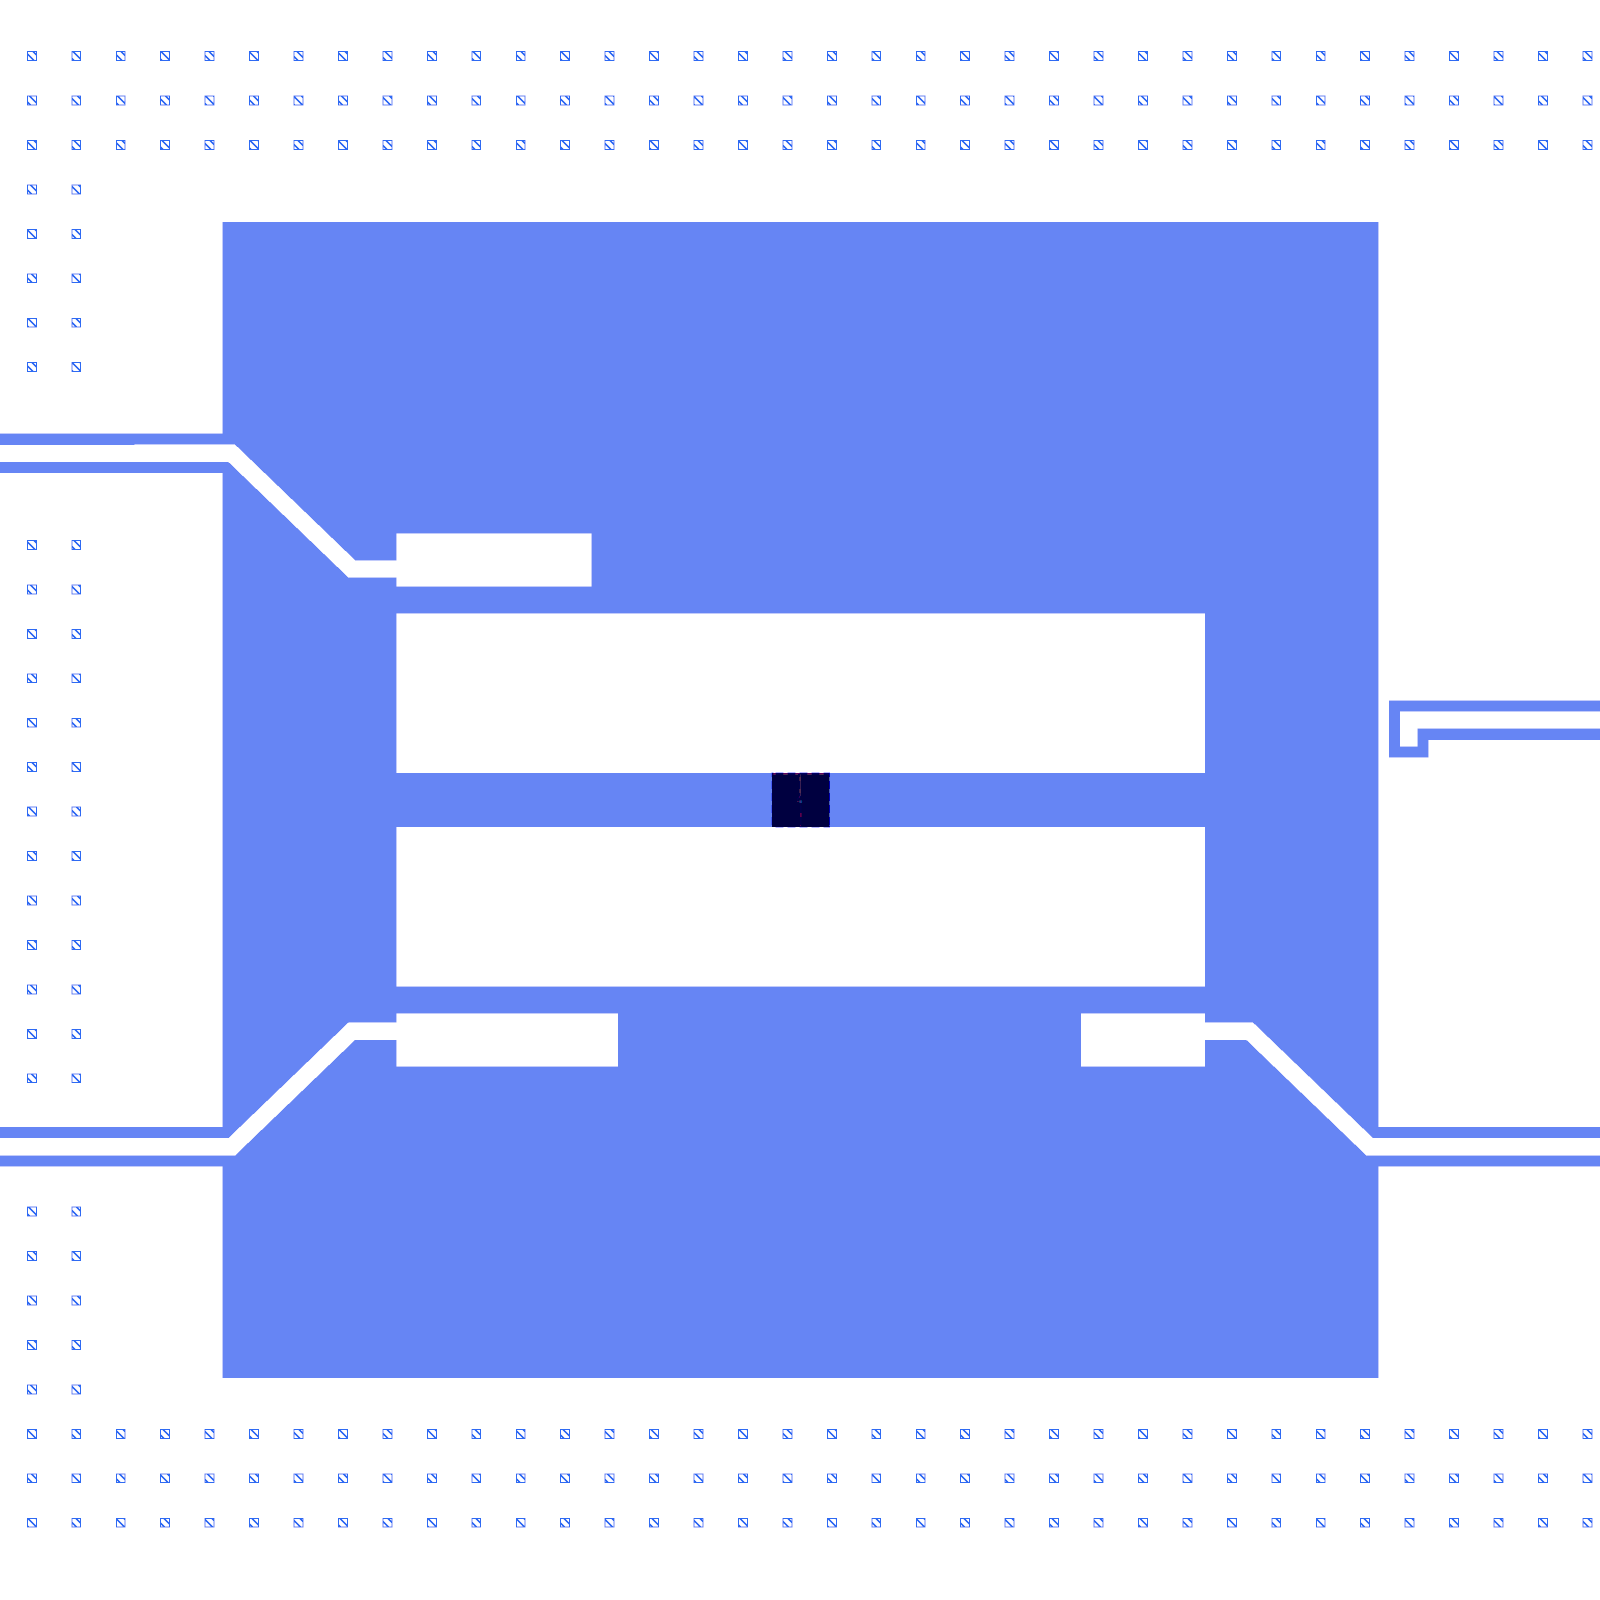

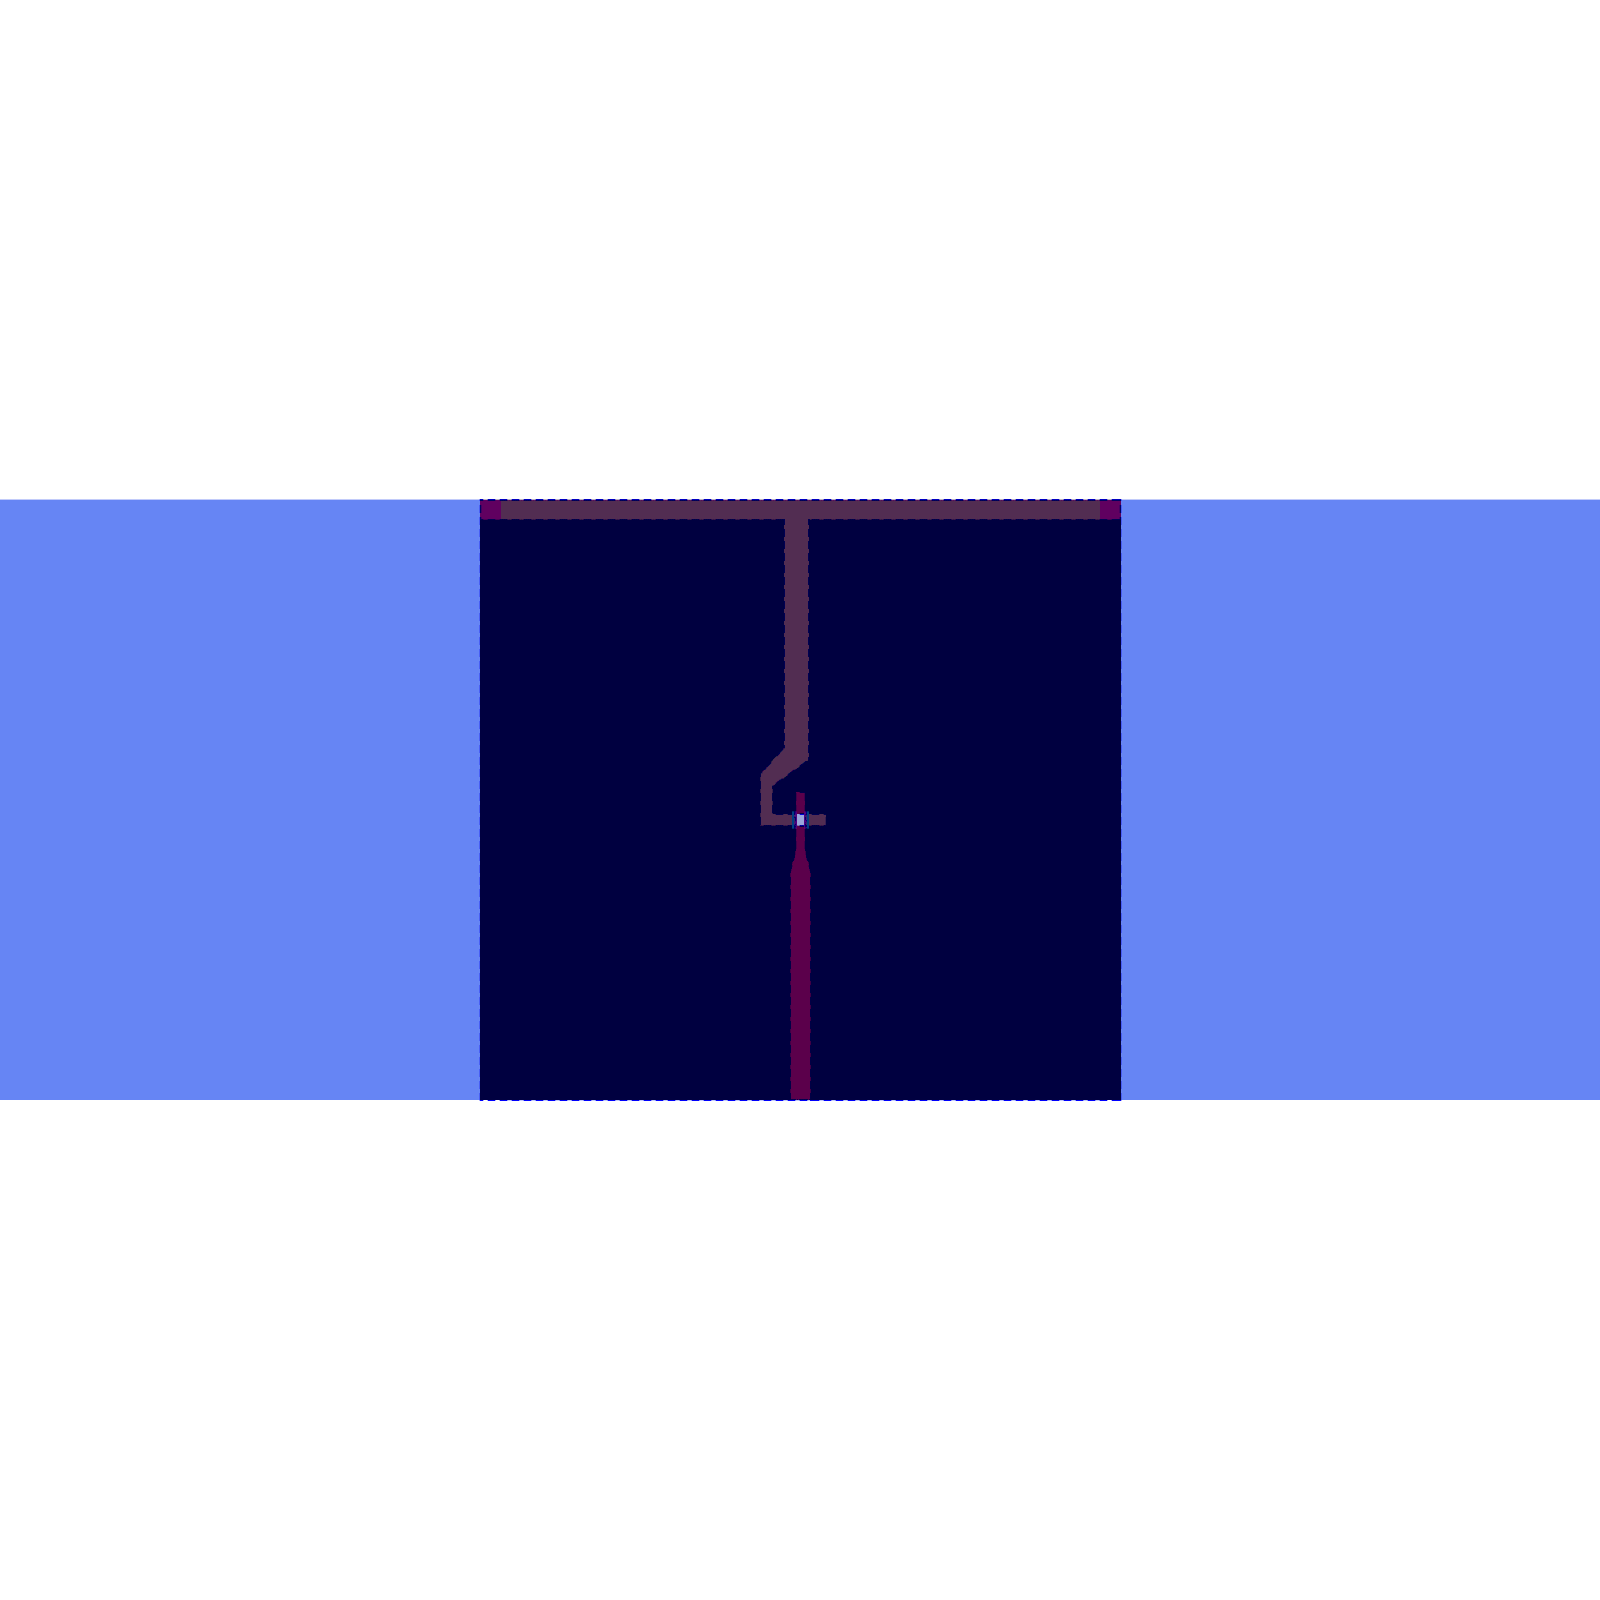

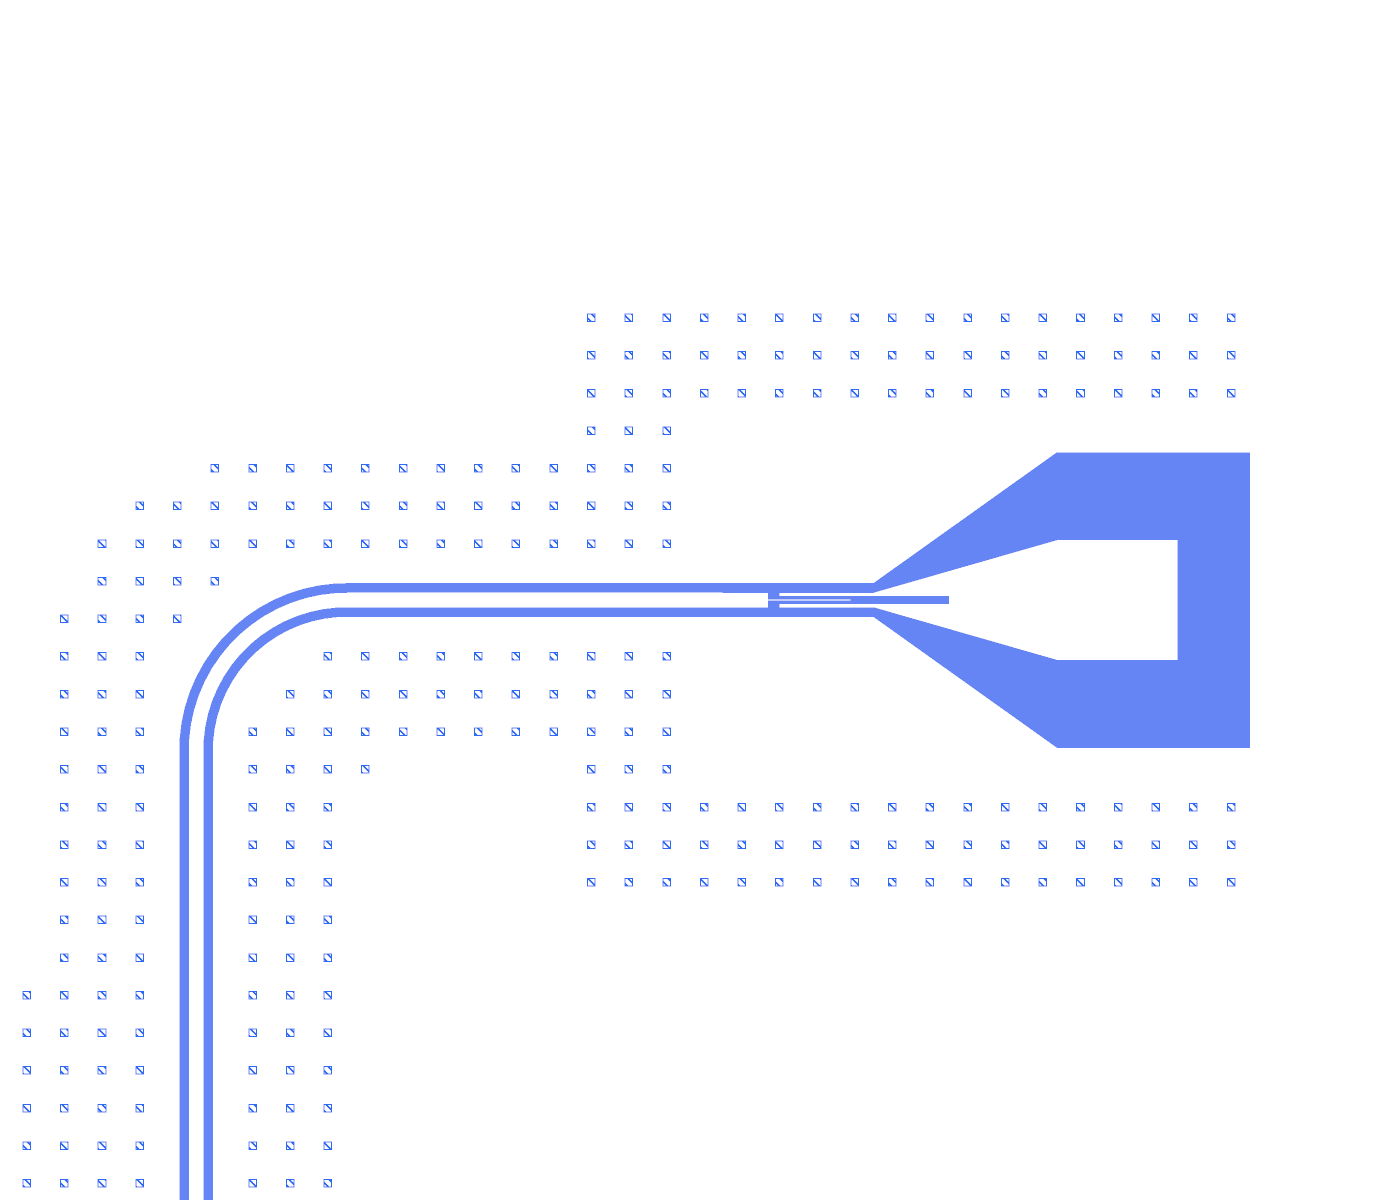

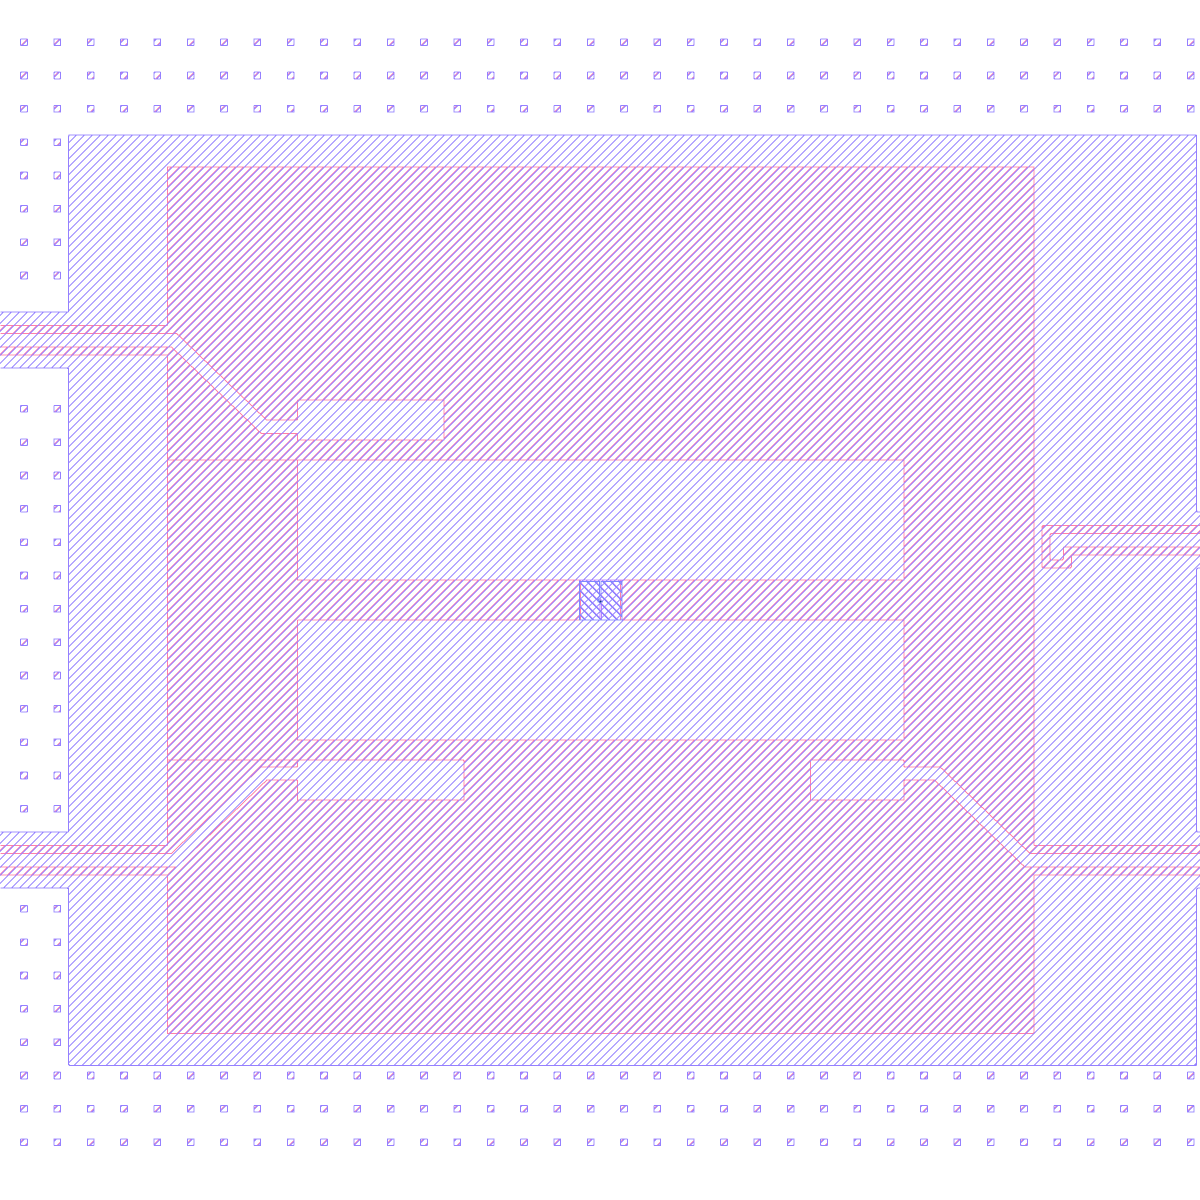

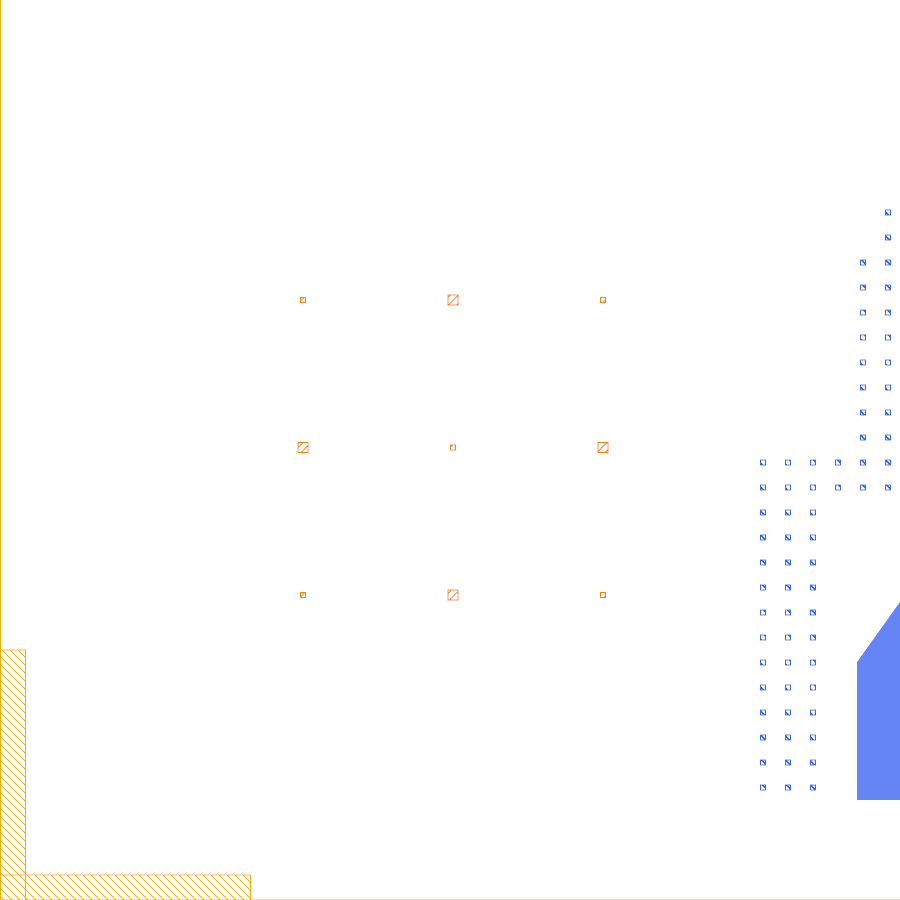

In [16]:
qx, qy = d.data["instances"]["Q1"]["place"]["at"]
px, py = d.data["instances"]["P1_Q"]["place"]["at"]
show_snapshot(d, OUT / "m51_four_qubit_chip.png", size=(1500, 1083))
show_snapshot(d, OUT / "m51_four_qubit_chip_q1.png", box=(qx - 450, qy - 450, qx + 450, qy + 450), width=420)
show_snapshot(d, OUT / "m51_four_qubit_chip_jj.png", box=(qx - 40, qy - 40, qx + 40, qy + 40), width=300)
show_snapshot(d, OUT / "m51_four_qubit_chip_pad.png", box=(px - 450, py - 300, 9000, py + 300), size=(1400, 1200),
              width=360)
snap_file(Path("build") / "m51_four_qubit_chip_fab.oas", OUT / "m51_four_qubit_chip_cheese.png",
          box=(qx - 450, qy - 450, qx + 450, qy + 450), size=(1200, 1200), width=420)
show_snapshot(d, OUT / "m51_four_qubit_chip_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300);

## 16 · Summary

| | |
|---|---|
| matches the source | every Metal component and option, the qubit and pad positions (pads along their edges), the route end pins, the bus (9000 µm) and readout (8600 µm) lengths, the sim groups |
| PDK changes | QCT frame on the source's 9 × 6.5 mm box; sapphire stack; eight launchpads 100 µm from the edges (were 178–230 µm); trilayer junctions (PDK nominal); PDK cheese band; content centred (no shift needed) |
| differs | the bus / readout serpentines are waypoint paths (Metal's `RouteMeander` asymmetry is not reproduced point for point); the readout runs are 22–33 µm shorter and the charge lines 78 µm longer because the pads moved; f_q ≈ 7.1 GHz with the PDK junction, above the ≈ 6.6 GHz buses and next to the 7.0 GHz readouts |
| PDK design warnings | none |
| LOM (this run) | f_q 7.126 GHz, α −437 MHz (all four identical); readouts 7.012 GHz, κ 2.7 MHz, χ +86 MHz (near-resonant: 114 MHz detuning); buses 6.58 GHz (QuCat), every qubit pair hybridised through its bus |
| open | the FEM jobs are exported, not solved (`RUN_FEM = False`) |